In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")
print(df.head())
print(df.info())

   Property_ID        City Locality_Type      Property_Type  BHK  Bathrooms  \
0  PROP-005003  Chandigarh     Mid-Range      Builder Floor    4          5   
1  PROP-009920     Kolkata       Premium      Builder Floor    2          2   
2  PROP-003987       Delhi     Mid-Range              Villa    3          4   
3  PROP-084186  Chandigarh     Mid-Range          Apartment    1          2   
4  PROP-068764   Ahmedabad       Premium  Independent House    5          5   

   Super_Area_SqFt  Carpet_Area_SqFt  Floor_Number  Total_Floors  \
0          1293.82            862.81            21            36   
1          2438.03           1977.23            16            31   
2          1065.54            721.68             2             3   
3          1611.76           1327.15            38            41   
4          1043.93            781.81            21            30   

   Age_of_Property Furnishing_Status  Parking  Lift_Available  \
0               11    Semi-Furnished        1      

In [7]:
print("Missing values: ")
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())
print("Dataset  shape: ", df.shape)

Missing values: 
Property_ID                   0
City                          0
Locality_Type                 0
Property_Type                 0
BHK                           0
Bathrooms                     0
Super_Area_SqFt               0
Carpet_Area_SqFt              0
Floor_Number                  0
Total_Floors                  0
Age_of_Property               0
Furnishing_Status             0
Parking                       0
Lift_Available                0
Gated_Community               0
Distance_to_Metro_km          0
Distance_to_City_Center_km    0
Price_INR_Lakhs               0
dtype: int64
Duplicate rows:  0
Dataset  shape:  (80000, 18)


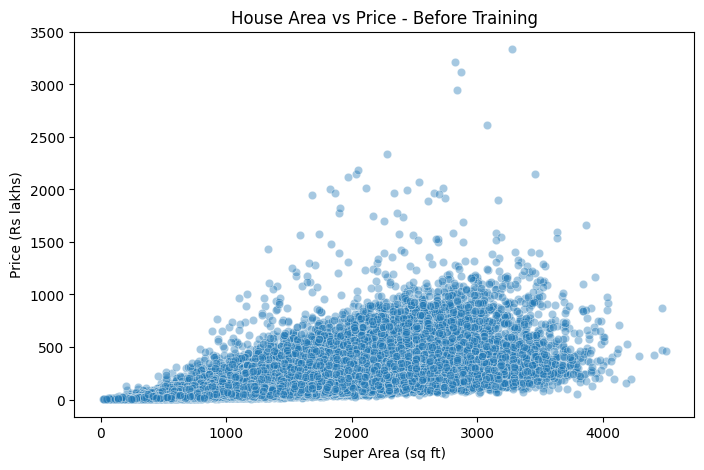

In [28]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data = df,
    x = "Super_Area_SqFt",
    y = "Price_INR_Lakhs",
    alpha = 0.4
)

plt.title("House Area vs Price - Before Training")
plt.xlabel("Super Area (sq ft)")
plt.ylabel("Price (Rs lakhs)")
plt.show()

In [8]:
X = df[["City" , "BHK" , "Bathrooms" ,"Super_Area_SqFt" , "Age_of_Property"]]
y = df["Price_INR_Lakhs"]

In [9]:
print(X.shape)
print(y.shape)

(80000, 5)
(80000,)


In [11]:
print(df["City"].unique())
print("Number of cities" , df["City"].nunique())

<StringArray>
['Chandigarh',    'Kolkata',      'Delhi',  'Ahmedabad',       'Pune',
  'Hyderabad',     'Mumbai',  'Bangalore',     'Jaipur',    'Chennai']
Length: 10, dtype: str
Number of cities 10


In [12]:
from sklearn.preprocessing import OneHotEncoder

In [13]:
encoder = OneHotEncoder(sparse_output=False)

In [14]:
encoder.fit(X[["City"]])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

In [15]:
print(encoder.categories_)

[array(['Ahmedabad', 'Bangalore', 'Chandigarh', 'Chennai', 'Delhi',
       'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai', 'Pune'], dtype=object)]


In [16]:
city_encoded = encoder.transform(X[["City"]])
print(city_encoded[:5])

[[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [17]:
print("Encoded shape: " , city_encoded.shape)
print("City columns: " , encoder.get_feature_names_out())

Encoded shape:  (80000, 10)
City columns:  ['City_Ahmedabad' 'City_Bangalore' 'City_Chandigarh' 'City_Chennai'
 'City_Delhi' 'City_Hyderabad' 'City_Jaipur' 'City_Kolkata' 'City_Mumbai'
 'City_Pune']


In [18]:
X_num = X[["BHK" , "Bathrooms" , "Super_Area_SqFt", "Age_of_Property"]]
# convert the encoded array into a dataframe
city_df = pd.DataFrame(
    city_encoded, 
    columns = encoder.get_feature_names_out(["City"]),
    index = X.index
    )

#combine both dataframes
X_final = pd.concat([city_df , X_num] , axis=1)
print(X_final.head())
print(X_final.shape)

   City_Ahmedabad  City_Bangalore  City_Chandigarh  City_Chennai  City_Delhi  \
0             0.0             0.0              1.0           0.0         0.0   
1             0.0             0.0              0.0           0.0         0.0   
2             0.0             0.0              0.0           0.0         1.0   
3             0.0             0.0              1.0           0.0         0.0   
4             1.0             0.0              0.0           0.0         0.0   

   City_Hyderabad  City_Jaipur  City_Kolkata  City_Mumbai  City_Pune  BHK  \
0             0.0          0.0           0.0          0.0        0.0    4   
1             0.0          0.0           1.0          0.0        0.0    2   
2             0.0          0.0           0.0          0.0        0.0    3   
3             0.0          0.0           0.0          0.0        0.0    1   
4             0.0          0.0           0.0          0.0        0.0    5   

   Bathrooms  Super_Area_SqFt  Age_of_Property  
0      

In [21]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(
    X_final , y , test_size = 0.2 , random_state = 42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(64000, 14)
(16000, 14)
(64000,)
(16000,)


In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[-66.87, 7.69,-14.87,..., -0.03, 0.15, -1.38]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['City_Ahmedabad','City_Bangalore','City_Chandigarh',...,'Bathrooms', 'Super_Area_SqFt','Age_of_Property']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-36.79
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,13


In [23]:
y_pred = model.predict(X_test)
print("Actual Prices: ")
print(y_test.head(10).values)

print("Predicted prices: ")
print(y_pred[:10])

Actual Prices: 
[333.73 112.09  66.9   30.08 177.49 120.97 348.51 152.95 121.86 173.84]
Predicted prices: 
[388.47759841  71.51496139  23.75527849  20.01364427 150.27020166
  84.01452416 268.69971223 129.98518604 203.05906367 191.63420574]


In [25]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

mae = mean_absolute_error(y_test , y_pred)
mse = mean_squared_error(y_test , y_pred)
r2 = r2_score(y_test , y_pred)

print("MAE: " ,mae)
print("MSE: " ,mse)
print("R2 Score: " ,r2)

MAE:  51.60208405248624
MSE:  8091.312924429767
R2 Score:  0.6345392952839628


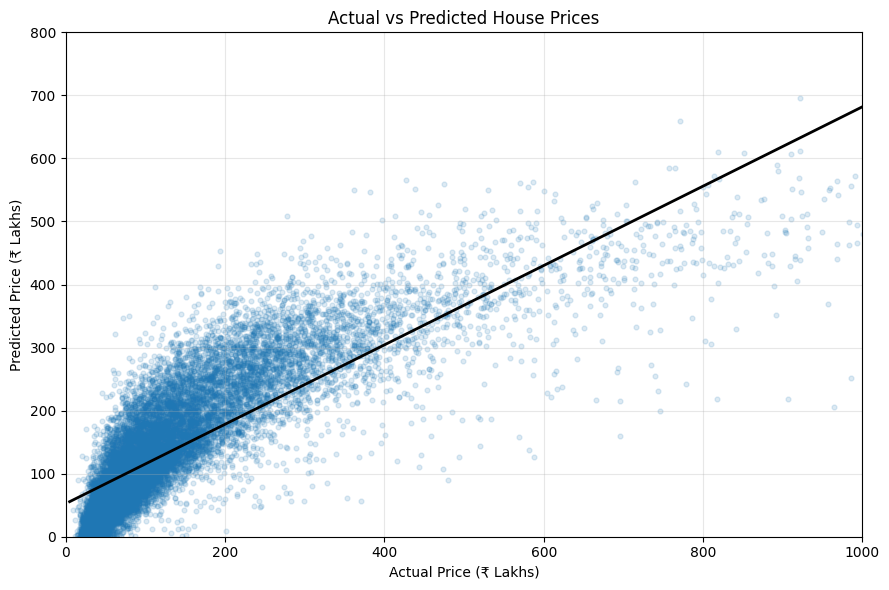

In [36]:
plt.figure(figsize=(9, 6))

sns.regplot(
    x=y_test,
    y=y_pred,
    scatter=True,
    scatter_kws={"alpha": 0.15, "s": 12},
    line_kws={"color": "black", "linewidth": 2},
    ci=None
)

plt.xlim(0, 1000)
plt.ylim(0, 800)

plt.xlabel("Actual Price (₹ Lakhs)")
plt.ylabel("Predicted Price (₹ Lakhs)")
plt.title("Actual vs Predicted House Prices")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()